# CA-4: Air Quality Prediction (Regression)
**Dataset:** UCI Air Quality (AirQualityUCI) | **Target:** `C6H6(GT)` (benzene concentration, µg/m³)
**Name / Roll No:** ______________ | **Submission:** 12/11/2026

**Business problem:** Reference gas analysers are expensive. Cheap metal-oxide sensors are noisy but can be *calibrated* with ML.
Goal: predict true benzene concentration from low-cost sensor readings + weather + time, so a cheap sensor node can replace an expensive analyser.

**Design choices:** features are low-cost sensors, weather (T, RH, AH) and time features. The reference-analyser columns (CO, NOx, NO2 ground truth) are excluded, because a real deployment would not have them. The sensor `PT08.S2(NMHC)` is also excluded after a data check (Section 7b) showing that it determines the target almost exactly.

## 0. Setup

In [1]:
# one-time install (run in a terminal):  pip install xgboost scikit-learn pandas seaborn matplotlib scipy openpyxl jupyter
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
sns.set_theme(style='whitegrid'); RS = 42

## 1. Load the dataset
Set `DATA_PATH` in the next cell to the location of `AirQualityUCI.csv` (or `.xlsx`) on your laptop.

In [2]:
import os
# >>> Put the path of the downloaded file here (CSV or XLSX). Example: r'C:\Users\Lalith\Downloads\AirQualityUCI.csv'
DATA_PATH = r'D:\Supervised learning project - Bihu sir\AirQualityUCI\AirQualityUCI.csv'
fname = DATA_PATH
if fname.lower().endswith(('.xlsx', '.xls')):
    df = pd.read_excel(fname)
else:
    df = pd.read_csv(fname, sep=';', decimal=',')
    if df.shape[1] < 5: df = pd.read_csv(fname)          # in case it is comma separated
df = df.loc[:, ~df.columns.astype(str).str.contains('Unnamed')].dropna(how='all')   # drop empty trailing cols/rows
# make Date / Time plain text in dd/mm/yyyy and hh:mm:ss, whatever the file format was
if pd.api.types.is_datetime64_any_dtype(df['Date']): df['Date'] = df['Date'].dt.strftime('%d/%m/%Y')
df['Date'] = df['Date'].astype(str).str[:10]
df['Time'] = df['Time'].astype(str).str.replace('.', ':', regex=False)
print(fname, df.shape); df.head()

D:\Supervised learning project - Bihu sir\AirQualityUCI\AirQualityUCI.csv (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 2. Dataset description

In [3]:
print('Rows, columns:', df.shape)
print('\nFeature types:'); print(df.dtypes.value_counts())
df.info()

Rows, columns: (9357, 15)

Feature types:
float64    13
str         2
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.2 MB


**Dataset summary:** 9,357 hourly records (10 Mar 2004 - 4 Apr 2005) from a road-level multisensor station; 15 columns (13 numeric + Date and Time as text).
- `Date`, `Time`: timestamp (converted to hour, month and weekend features)
- `PT08.S1(CO)`, `PT08.S2(NMHC)`, `PT08.S3(NOx)`, `PT08.S4(NO2)`, `PT08.S5(O3)`: low-cost metal-oxide sensor responses (**features**; S2 is excluded after the check in Section 7b)
- `T`, `RH`, `AH`: temperature, relative humidity, absolute humidity (**features**)
- `CO(GT)`, `NMHC(GT)`, `NOx(GT)`, `NO2(GT)`: reference analyser values (not used as features)
- `C6H6(GT)`: benzene in ug/m3 -> **target** (range 0.1-63.7, mean 10.08, median 8.2, skew 1.36)

## 3. Missing value analysis
In this dataset missing values are stored as **-200**, not NaN. Convert them first.

,missing,pct
NMHC(GT),8443,90.2
CO(GT),1683,18.0
NOx(GT),1639,17.5
NO2(GT),1642,17.5
PT08.S2(NMHC),366,3.9
C6H6(GT),366,3.9
PT08.S1(CO),366,3.9
PT08.S5(O3),366,3.9
T,366,3.9
PT08.S3(NOx),366,3.9


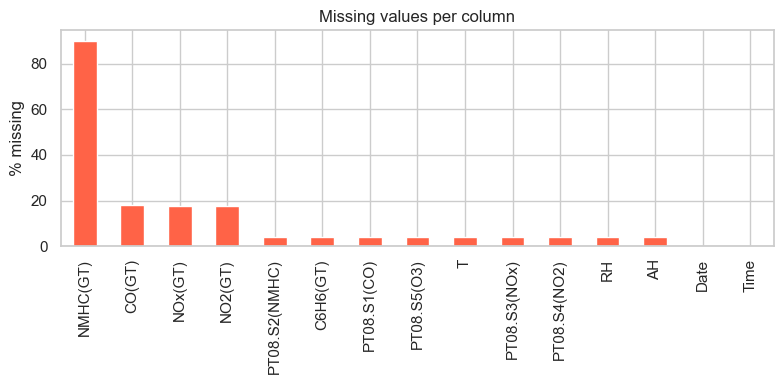

In [4]:
df = df.replace(-200, np.nan)
miss = pd.DataFrame({'missing': df.isna().sum(), 'pct': (df.isna().mean()*100).round(1)}).sort_values('pct', ascending=False)
display(miss)
plt.figure(figsize=(8,4)); miss['pct'].plot.bar(color='tomato'); plt.ylabel('% missing'); plt.title('Missing values per column')
plt.tight_layout(); plt.savefig('fig_missing.png', dpi=150); plt.show()

In [5]:
# Decisions
# 1) NMHC(GT) is ~90% missing -> drop.   2) Rows with missing TARGET cannot be used -> drop.
# 3) Remaining feature gaps are imputed with the MEDIAN inside the model pipeline (fit on train only -> no leakage).
df = df.drop(columns=['NMHC(GT)'])
TARGET = 'C6H6(GT)'
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print('After dropping missing-target rows:', df.shape)

After dropping missing-target rows: (8991, 14)


## 4. Feature engineering & encoding
Date/Time are text. Convert to numeric time features (hour, month, weekday). Cyclical encoding (sin/cos) so hour 23 and hour 0 are close.

In [6]:
ts = pd.to_datetime(df['Date'] + ' ' + df['Time'], dayfirst=True, errors='coerce')
print('Unparsed timestamps:', ts.isna().sum())
df['hour'] = ts.dt.hour; df['month'] = ts.dt.month; df['weekday'] = ts.dt.weekday
df['hour_sin'] = np.sin(2*np.pi*df['hour']/24); df['hour_cos'] = np.cos(2*np.pi*df['hour']/24)
df['is_weekend'] = (df['weekday']>=5).astype(int)
df['timestamp'] = ts

SENSORS = ['PT08.S1(CO)','PT08.S2(NMHC)','PT08.S3(NOx)','PT08.S4(NO2)','PT08.S5(O3)']
WEATHER = ['T','RH','AH']
TIME    = ['hour_sin','hour_cos','month','is_weekend']
FEATURES = SENSORS + WEATHER + TIME
print('Features used:', FEATURES)

Unparsed timestamps: 0
Features used: ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'hour_sin', 'hour_cos', 'month', 'is_weekend']


## 5. Outlier detection (IQR + boxplots)

,column,outliers_IQR,pct
0,PT08.S1(CO),118,1.3
1,PT08.S2(NMHC),65,0.7
2,PT08.S3(NOx),241,2.7
3,PT08.S4(NO2),97,1.1
4,PT08.S5(O3),93,1.0
5,T,3,0.0
6,RH,0,0.0
7,AH,2,0.0
8,C6H6(GT),228,2.5


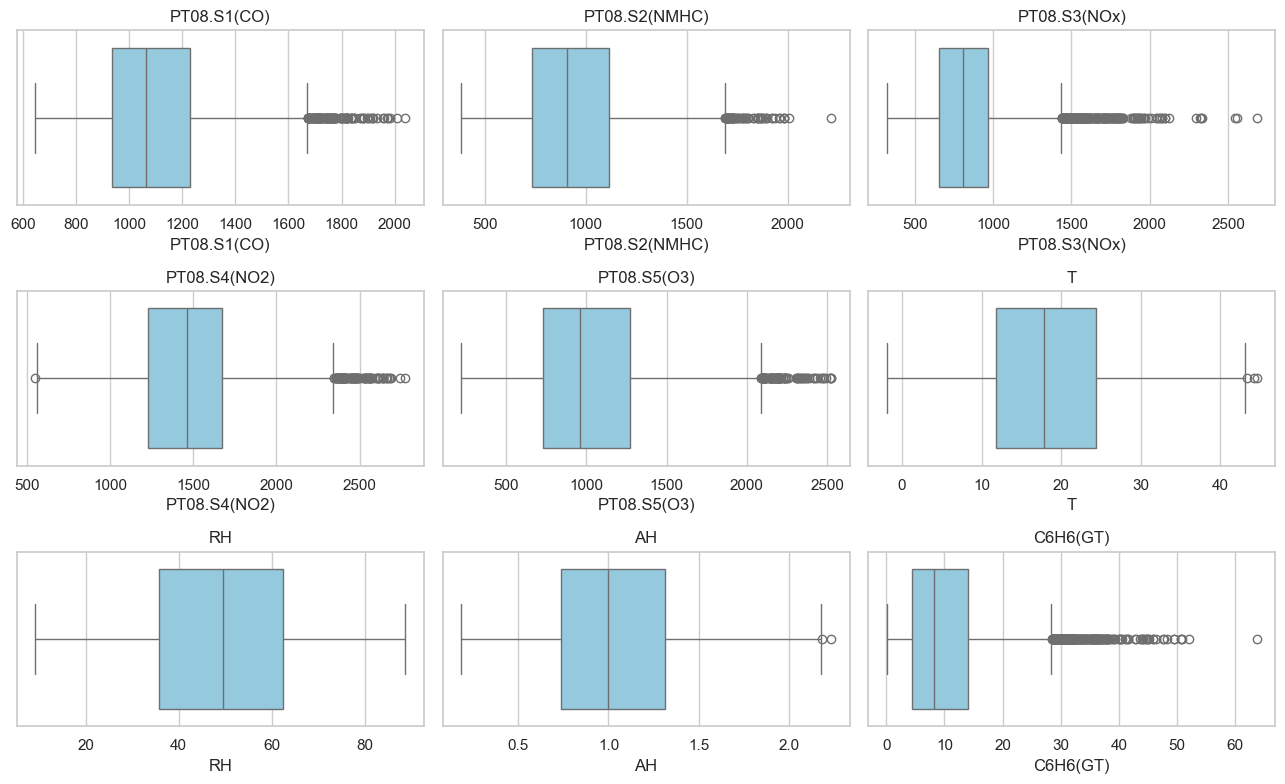

In [7]:
num = SENSORS + WEATHER + [TARGET]
rows = []
for c in num:
    q1, q3 = df[c].quantile([.25,.75]); iqr = q3-q1
    n = ((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum()
    rows.append((c, n, round(n/df[c].notna().sum()*100,1)))
display(pd.DataFrame(rows, columns=['column','outliers_IQR','pct']))
fig, axes = plt.subplots(3,3, figsize=(13,8))
for ax,c in zip(axes.ravel(), num): sns.boxplot(x=df[c], ax=ax, color='skyblue'); ax.set_title(c)
plt.tight_layout(); plt.savefig('fig_outliers.png', dpi=150); plt.show()

**Decision:** these are real pollution peaks (rush-hour spikes), not data errors, so I **keep** them. Tree-based models are robust to them; for Linear Regression/KNN I standardise features. (Mention this in the report.)

## 6. Distribution analysis

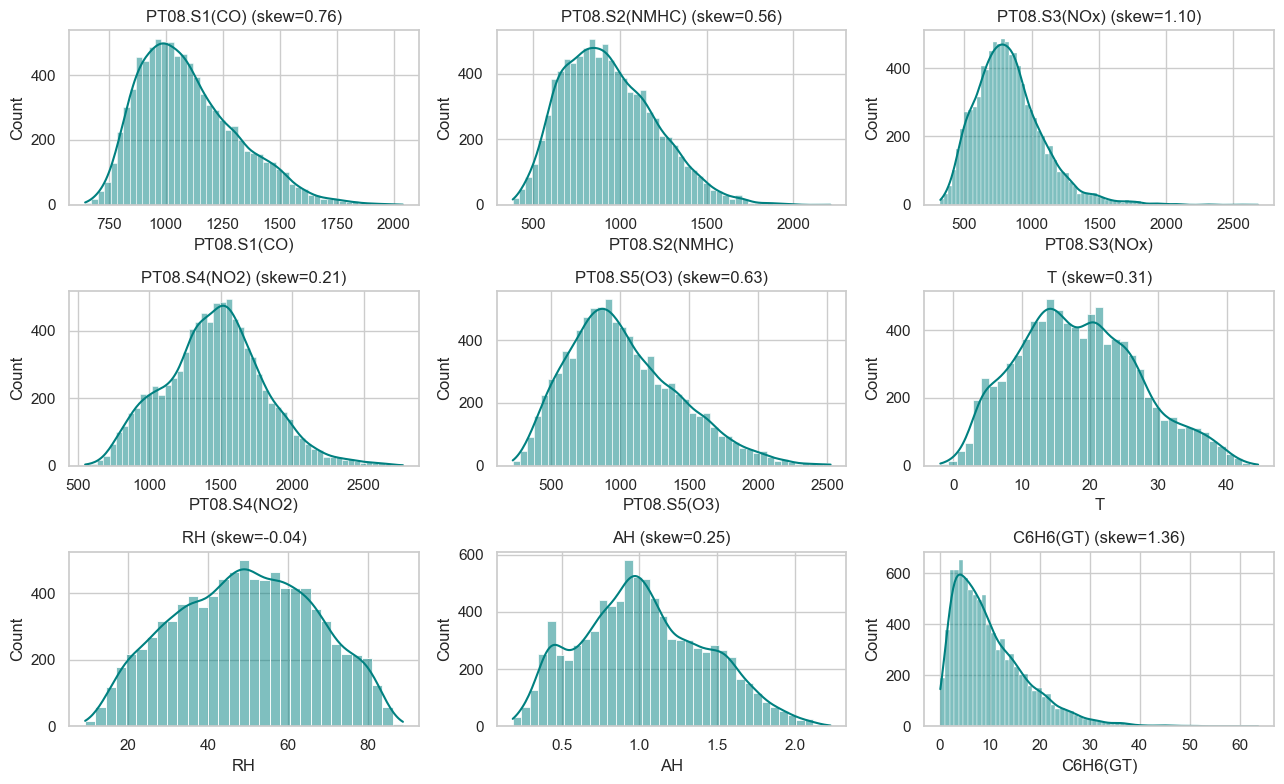

In [8]:
fig, axes = plt.subplots(3,3, figsize=(13,8))
for ax,c in zip(axes.ravel(), num):
    sns.histplot(df[c].dropna(), kde=True, ax=ax, color='teal'); ax.set_title(f'{c} (skew={df[c].skew():.2f})')
plt.tight_layout(); plt.savefig('fig_distributions.png', dpi=150); plt.show()

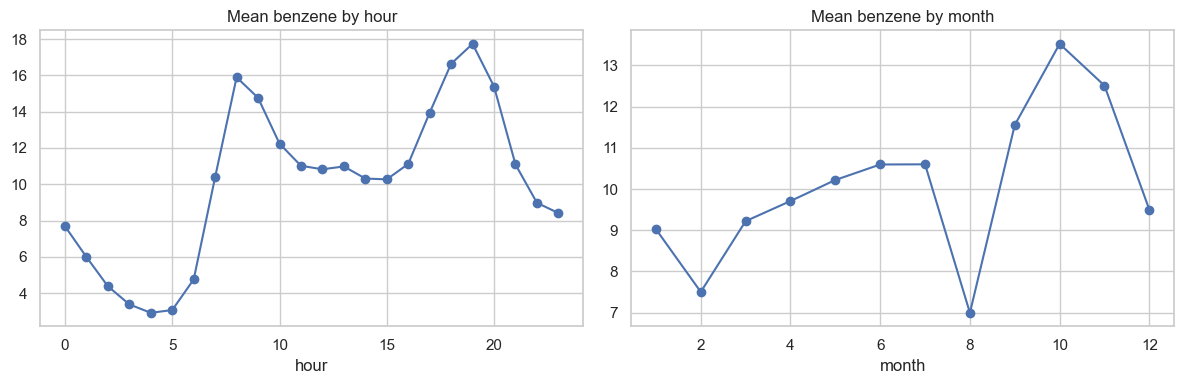

In [9]:
# Target is right-skewed; also look at it by hour of day and by month (pollution has a daily cycle)
fig, ax = plt.subplots(1,2, figsize=(12,4))
df.groupby('hour')[TARGET].mean().plot(ax=ax[0], marker='o'); ax[0].set_title('Mean benzene by hour')
df.groupby('month')[TARGET].mean().plot(ax=ax[1], marker='o'); ax[1].set_title('Mean benzene by month')
plt.tight_layout(); plt.savefig('fig_target_time.png', dpi=150); plt.show()

## 7. Correlation analysis

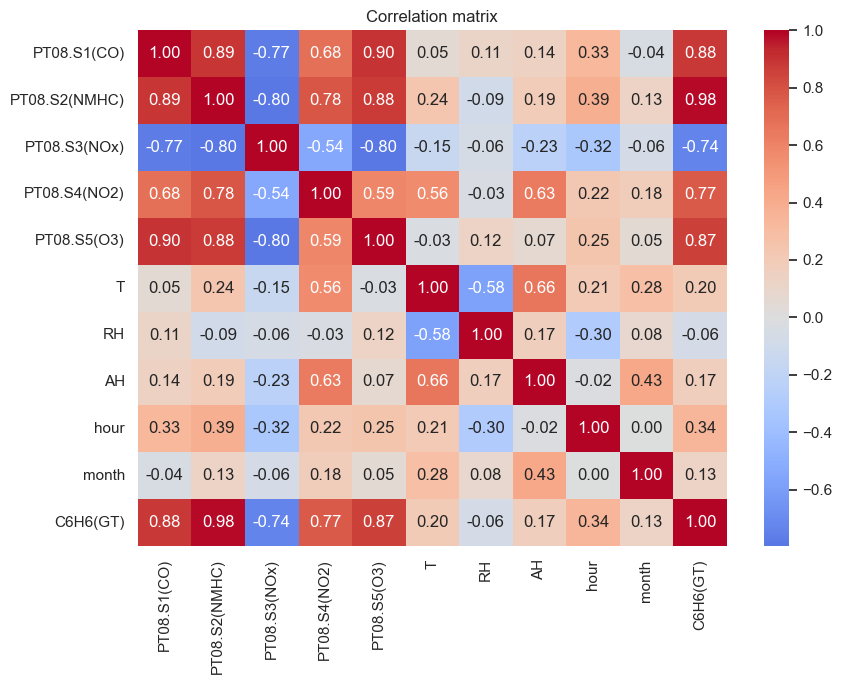

PT08.S2(NMHC)    0.981950
PT08.S1(CO)      0.883795
PT08.S5(O3)      0.865689
PT08.S4(NO2)     0.765731
hour             0.344169
T                0.198956
AH               0.167972
month            0.128537
RH              -0.061681
PT08.S3(NOx)    -0.735744
Name: C6H6(GT), dtype: float64


In [10]:
corr = df[SENSORS+WEATHER+['hour','month',TARGET]].corr()
plt.figure(figsize=(9,7)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('fig_corr.png', dpi=150); plt.show()
print(corr[TARGET].drop(TARGET).sort_values(ascending=False))

**Observations:** `PT08.S2(NMHC)` has an extremely strong correlation with benzene (r = 0.98), followed by `PT08.S1(CO)` (0.88), `PT08.S5(O3)` (0.87) and `PT08.S4(NO2)` (0.77); `PT08.S3(NOx)` is negatively correlated (-0.74). Weather and time are weak (hour 0.34, T 0.20, AH 0.17, month 0.13, RH -0.06).
The sensors are strongly correlated with each other (e.g. S1-S5 0.90) -> **multicollinearity**, which makes Linear Regression coefficients unstable but does not hurt tree ensembles.

## 7b. Data check: does one sensor determine the target?
`PT08.S2(NMHC)` has r = 0.98 with benzene. Before modelling we test whether it *alone* explains the target.

Rows: 8991 | distinct S2 values: 1245
S2 values that occur more than once: 1055 | of these, with >1 distinct benzene value: 167
Largest benzene spread among rows with the SAME S2 value: 0.1 ug/m3 (data precision is 0.1)
Decision Tree using ONLY PT08.S2(NMHC) -> test MAE 0.0105, RMSE 0.0520, R2 1.0000


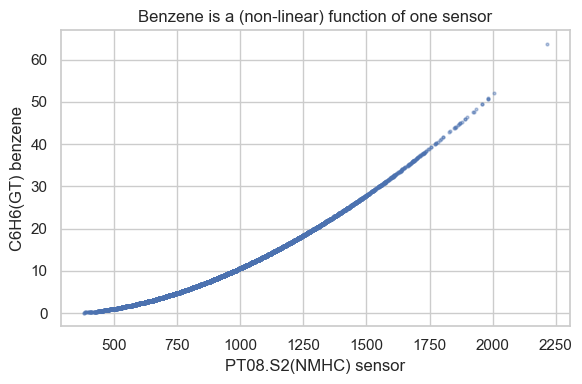

In [11]:
d_chk = df[['PT08.S2(NMHC)', TARGET]].dropna()
g = d_chk.groupby('PT08.S2(NMHC)')[TARGET]
print('Rows:', len(d_chk), '| distinct S2 values:', g.ngroups)
print('S2 values that occur more than once:', int((g.size() > 1).sum()), '| of these, with >1 distinct benzene value:', int((g.nunique() > 1).sum()))
print('Largest benzene spread among rows with the SAME S2 value:', round(float(g.agg(lambda s: s.max()-s.min()).max()), 2), 'ug/m3 (data precision is 0.1)')
_a, _b, _c, _d = train_test_split(d_chk[['PT08.S2(NMHC)']], d_chk[TARGET], test_size=0.30, random_state=RS)
_t = DecisionTreeRegressor(random_state=RS).fit(_a, _c); _p = _t.predict(_b)
print('Decision Tree using ONLY PT08.S2(NMHC) -> test MAE %.4f, RMSE %.4f, R2 %.4f' % (mean_absolute_error(_d,_p), np.sqrt(mean_squared_error(_d,_p)), r2_score(_d,_p)))
plt.figure(figsize=(6,4)); plt.scatter(d_chk['PT08.S2(NMHC)'], d_chk[TARGET], s=4, alpha=.4)
plt.xlabel('PT08.S2(NMHC) sensor'); plt.ylabel('C6H6(GT) benzene'); plt.title('Benzene is a (non-linear) function of one sensor')
plt.tight_layout(); plt.savefig('fig_S2_vs_benzene.png', dpi=150); plt.show()

**Finding:** whenever the S2 sensor shows the same value, benzene is the same (to the data's 0.1 rounding). A tree that sees only this column reaches R² ≈ 1.000.
In this dataset benzene is therefore effectively a look-up function of one column, so keeping it would give a perfect but meaningless score (the model would not be calibrating anything).
**Decision:** exclude `PT08.S2(NMHC)`, so the model must work from the remaining sensors, weather and time. This is the realistic sensor-calibration problem.

In [12]:
FEATURES = [f for f in FEATURES if f != 'PT08.S2(NMHC)']
print('Features used for modelling (S2 excluded):', FEATURES)

Features used for modelling (S2 excluded): ['PT08.S1(CO)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'hour_sin', 'hour_cos', 'month', 'is_weekend']


## 8. Train / Test split (70 / 30)

In [13]:
X = df[FEATURES]; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (6293, 11)  Test: (2698, 11)


# Baseline Modeling

In [14]:
def metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

def make(model, scale=False):
    steps = [('imp', SimpleImputer(strategy='median'))]
    if scale: steps.append(('sc', StandardScaler()))
    steps.append(('m', model))
    return Pipeline(steps)

baselines = {
    'Linear Regression': make(LinearRegression(), scale=True),
    'Decision Tree':     make(DecisionTreeRegressor(random_state=RS)),
    'KNN (k=5)':         make(KNeighborsRegressor(n_neighbors=5), scale=True),
}
results = {}
for name, pipe in baselines.items():
    pipe.fit(X_train, y_train)
    results[name] = {**{f'Train {k}': v for k,v in metrics(y_train, pipe.predict(X_train)).items() if k=='R2'},
                     **metrics(y_test, pipe.predict(X_test))}
base_df = pd.DataFrame(results).T.round(3)
base_df

,Train R2,MAE,RMSE,R2
Linear Regression,0.921,1.515,2.078,0.927
Decision Tree,1.000,1.178,1.782,0.946
KNN (k=5),0.973,0.995,1.533,0.960


### Interpretation (baseline, S2 excluded)
- **Linear Regression:** test R² = 0.927, MAE 1.515, RMSE 2.078. Train R² (0.921) is close to test R², so it is not overfitting; it is limited because sensor response is non-linear.
- **Decision Tree:** train R² = 1.000 but test R² = 0.946 -> clear **overfitting** (memorises the training set).
- **KNN (k=5):** test R² = 0.960, MAE 0.995, RMSE 1.533, the **best baseline**. Scaling was essential because sensors have very different ranges.
- Next step: ensembles (bagging/boosting) and hyperparameter tuning should reduce variance and capture the non-linear sensor response.

# Advanced Modeling & Optimization

### 9. Cross-validation of all models (5-fold on the training set)

In [15]:
kf = KFold(n_splits=5, shuffle=True, random_state=RS)
all_models = {
    **baselines,
    'Random Forest':     make(RandomForestRegressor(n_estimators=200, random_state=RS, n_jobs=-1)),
    'Gradient Boosting': make(GradientBoostingRegressor(random_state=RS)),
    'XGBoost':           make(XGBRegressor(random_state=RS, n_jobs=-1, verbosity=0)),
}
cv_rows = {}
for name, pipe in all_models.items():
    s = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2', n_jobs=-1)
    cv_rows[name] = {'CV R2 mean': s.mean(), 'CV R2 std': s.std()}
cv_df = pd.DataFrame(cv_rows).T.round(4); cv_df

,CV R2 mean,CV R2 std
Linear Regression,0.9207,0.0058
Decision Tree,0.9340,0.0079
KNN (k=5),0.9532,0.0048
Random Forest,0.9694,0.0070
Gradient Boosting,0.9652,0.0071
XGBoost,0.9735,0.0066


### 10. Hyperparameter tuning (GridSearchCV)

In [16]:
rf_grid = {'m__n_estimators':[300], 'm__max_depth':[None,20], 'm__min_samples_leaf':[1,3], 'm__max_features':[0.6,1.0]}
gs_rf = GridSearchCV(make(RandomForestRegressor(random_state=RS, n_jobs=-1)), rf_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0)
gs_rf.fit(X_train, y_train)
print('RF best params:', gs_rf.best_params_, '| CV RMSE:', round(-gs_rf.best_score_,3))

RF best params: {'m__max_depth': 20, 'm__max_features': 0.6, 'm__min_samples_leaf': 1, 'm__n_estimators': 300} | CV RMSE: 1.264


In [17]:
xgb_grid = {'m__n_estimators':[300,500], 'm__max_depth':[4,6], 'm__learning_rate':[0.05,0.1]}
gs_xgb = GridSearchCV(make(XGBRegressor(random_state=RS, n_jobs=-1, verbosity=0)), xgb_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0)
gs_xgb.fit(X_train, y_train)
print('XGB best params:', gs_xgb.best_params_, '| CV RMSE:', round(-gs_xgb.best_score_,3))

XGB best params: {'m__learning_rate': 0.1, 'm__max_depth': 4, 'm__n_estimators': 500} | CV RMSE: 1.034


In [18]:
gb_grid = {'m__n_estimators':[300], 'm__max_depth':[3,5], 'm__learning_rate':[0.05,0.1], 'm__subsample':[0.8]}
gs_gb = GridSearchCV(make(GradientBoostingRegressor(random_state=RS)), gb_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0)
gs_gb.fit(X_train, y_train)
print('GB best params:', gs_gb.best_params_, '| CV RMSE:', round(-gs_gb.best_score_,3))

GB best params: {'m__learning_rate': 0.1, 'm__max_depth': 5, 'm__n_estimators': 300, 'm__subsample': 0.8} | CV RMSE: 1.039


### 11. Final comparison on the held-out test set

,MAE,RMSE,R2
Gradient Boosting (tuned),0.610,0.944,0.985
XGBoost (tuned),0.620,0.962,0.984
Random Forest (tuned),0.785,1.235,0.974
KNN (k=5),0.995,1.533,0.960
Decision Tree,1.178,1.782,0.946
Linear Regression,1.515,2.078,0.927


Best model on test set: Gradient Boosting (tuned)


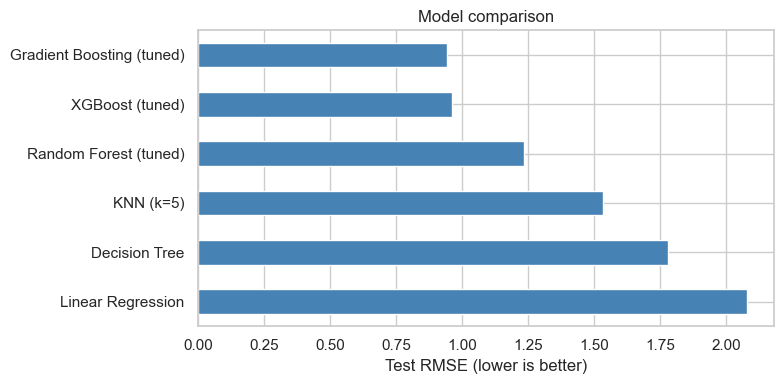

In [19]:
tuned = {'Random Forest (tuned)': gs_rf.best_estimator_,
         'Gradient Boosting (tuned)': gs_gb.best_estimator_,
         'XGBoost (tuned)': gs_xgb.best_estimator_}
rows = {n: metrics(y_test, m.predict(X_test)) for n, m in tuned.items()}
for n, m in baselines.items(): rows[n] = metrics(y_test, m.predict(X_test))
final_df = pd.DataFrame(rows).T.sort_values('RMSE').round(3)
display(final_df)
best_name = final_df.index[0]
best_model = {**tuned, **baselines}[best_name]
print('Best model on test set:', best_name)

ax = final_df['RMSE'].sort_values(ascending=False).plot.barh(color='steelblue', figsize=(8,4))
ax.set_xlabel('Test RMSE (lower is better)'); plt.title('Model comparison'); plt.tight_layout()
plt.savefig('fig_model_compare.png', dpi=150); plt.show()

### 12. Predicted vs Actual and Residual analysis (best model)

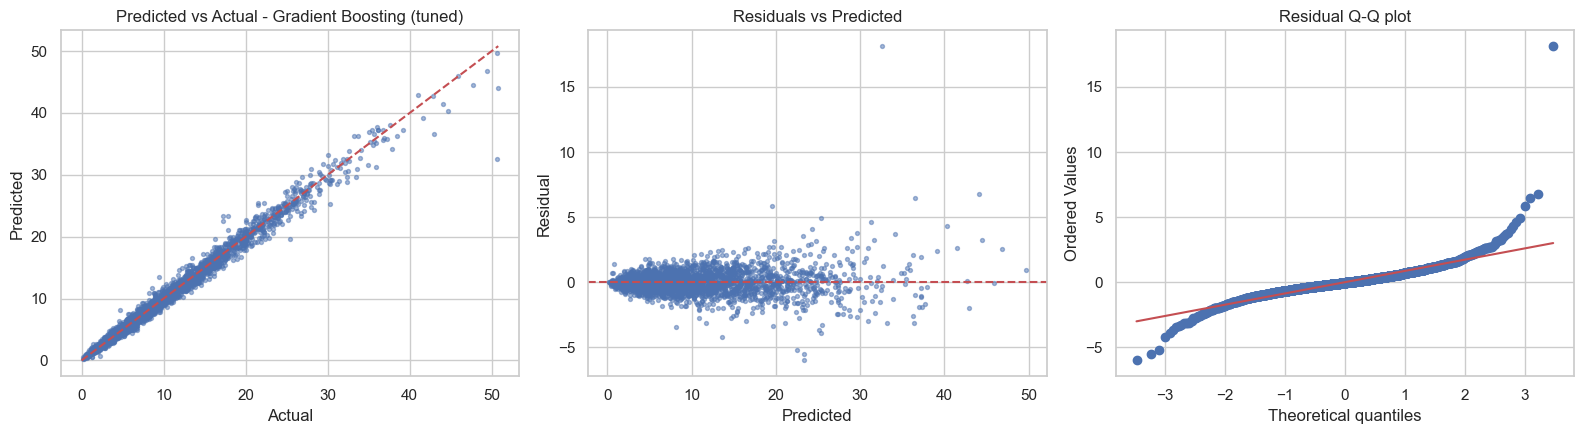

Residual mean = 0.011, std = 0.944, skew = 2.89


In [20]:
pred = best_model.predict(X_test); resid = y_test - pred
fig, ax = plt.subplots(1,3, figsize=(16,4.5))
ax[0].scatter(y_test, pred, s=8, alpha=.5); lim=[0, max(y_test.max(), pred.max())]; ax[0].plot(lim, lim, 'r--')
ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title(f'Predicted vs Actual - {best_name}')
ax[1].scatter(pred, resid, s=8, alpha=.5); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residuals vs Predicted')
stats.probplot(resid, dist='norm', plot=ax[2]); ax[2].set_title('Residual Q-Q plot')
plt.tight_layout(); plt.savefig('fig_residuals.png', dpi=150); plt.show()
print(f'Residual mean = {resid.mean():.3f}, std = {resid.std():.3f}, skew = {stats.skew(resid):.2f}')

**Residual analysis (final model):** points follow the red diagonal closely, and residuals are centred on zero (mean 0.011, SD 0.944). The spread is roughly constant up to about 20 ug/m3 and widens above it (**heteroscedasticity**), so predictions are less reliable during pollution peaks. The Q-Q plot shows heavy tails: a few large misses on rare high-benzene hours (one hour near 50 ug/m3 is under-predicted by about 18 ug/m3).

### 13. Feature importance

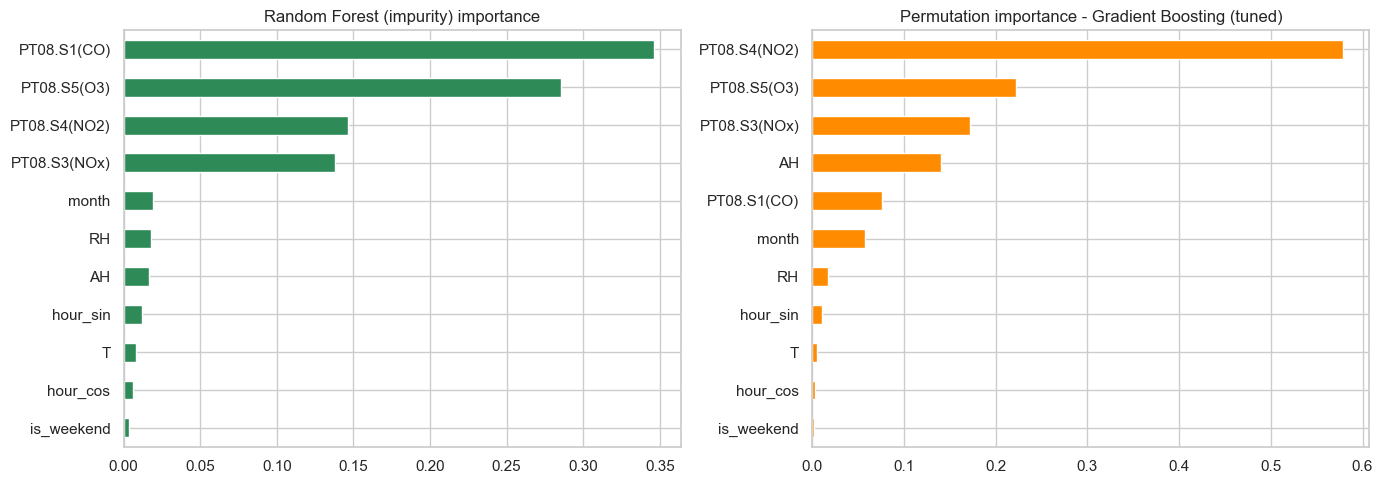

In [21]:
rf = gs_rf.best_estimator_.named_steps['m']
imp_rf = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=RS, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(1,2, figsize=(14,5))
imp_rf.plot.barh(ax=ax[0], color='seagreen'); ax[0].set_title('Random Forest (impurity) importance')
imp_perm.plot.barh(ax=ax[1], color='darkorange'); ax[1].set_title(f'Permutation importance - {best_name}')
plt.tight_layout(); plt.savefig('fig_importance.png', dpi=150); plt.show()

### 14. Realistic check: forward-in-time (chronological) test
The data is a time series. A random split lets the model see hours right before and after every test hour. In deployment the model must predict **future** hours, so here we train on the first 70% of the timeline (Mar-Dec 2004) and test on the last 30% (Dec 2004-Apr 2005).

In [22]:
from sklearn.base import clone
d2 = df.sort_values('timestamp').reset_index(drop=True)
cut = int(len(d2)*0.7)
print('Train period:', d2['timestamp'].iloc[0], '->', d2['timestamp'].iloc[cut-1])
print('Test period :', d2['timestamp'].iloc[cut], '->', d2['timestamp'].iloc[-1])
Xtr, Xte = d2.loc[:cut-1, FEATURES], d2.loc[cut:, FEATURES]
ytr, yte = d2.loc[:cut-1, TARGET], d2.loc[cut:, TARGET]
print('Mean benzene: train %.2f | test %.2f' % (ytr.mean(), yte.mean()))
all_final = {**tuned, **baselines}
rows_t = {n: metrics(yte, clone(m).fit(Xtr, ytr).predict(Xte)) for n, m in all_final.items()}
time_df = pd.DataFrame(rows_t).T.round(3)
cmp_df = pd.concat([final_df[['RMSE','R2']].add_prefix('Random split '), time_df[['RMSE','R2']].add_prefix('Time split ')], axis=1).sort_values('Time split RMSE')
display(cmp_df)

Train period: 2004-03-10 18:00:00 -> 2004-12-04 02:00:00
Test period : 2004-12-04 03:00:00 -> 2005-04-04 14:00:00
Mean benzene: train 10.81 | test 8.39


,Random split RMSE,Random split R2,Time split RMSE,Time split R2
KNN (k=5),1.533,0.960,2.251,0.884
Gradient Boosting (tuned),0.944,0.985,3.253,0.757
XGBoost (tuned),0.962,0.984,3.424,0.731
Random Forest (tuned),1.235,0.974,3.644,0.695
Decision Tree,1.782,0.946,4.326,0.570
Linear Regression,2.078,0.927,8.375,-0.611


In [23]:
gb_t = clone(tuned['Gradient Boosting (tuned)']).fit(Xtr, ytr)
bias = (yte - gb_t.predict(Xte)).groupby(d2.loc[cut:, 'timestamp'].dt.to_period('M')).agg(['mean','size']).round(2)
print('Mean residual (actual - predicted) by month, Gradient Boosting, time split:'); print(bias)

Mean residual (actual - predicted) by month, Gradient Boosting, time split:
           mean  size
timestamp            
2004-12   -0.95   589
2005-01   -1.86   683
2005-02   -3.17   596
2005-03   -2.88   743
2005-04   -2.50    87


In [24]:
# Sensitivity: the 'month' feature takes values never seen in training (Jan, Feb) -> drop it and compare
F_nm = [f for f in FEATURES if f != 'month']
rows_nm = {n: metrics(yte, clone(all_final[n]).fit(Xtr[F_nm], ytr).predict(Xte[F_nm])) for n in ['Linear Regression','KNN (k=5)','Gradient Boosting (tuned)','XGBoost (tuned)']}
display(pd.DataFrame(rows_nm).T.round(3))

,MAE,RMSE,R2
Linear Regression,1.995,2.574,0.848
KNN (k=5),2.115,2.780,0.823
Gradient Boosting (tuned),2.536,3.588,0.704
XGBoost (tuned),2.415,3.611,0.701


**Reading the forward-in-time test:** every model loses accuracy on future hours, so the random-split scores (R² up to 0.985) are optimistic. Gradient Boosting drops to R² ≈ 0.76 (RMSE ≈ 3.3 ug/m3) and KNN to R² ≈ 0.88 (RMSE ≈ 2.3). The mean residual becomes increasingly negative from December onward, i.e. the model **over-predicts** later months: the sensors' response drifts over time (a known issue with metal-oxide sensors), so the relation learnt in 2004 no longer holds exactly in 2005.
Linear Regression collapses (R² < 0) only because the `month` feature extrapolates to months it has never seen; without `month` it reaches about 0.85. Realistic expectation for future data: **R² roughly 0.7-0.9 (RMSE 2.3-3.6 ug/m3)**, and periodic **recalibration** is needed.

# Interpretation, Documentation & Deployment Insight

### Final model selection
Selected: **tuned Gradient Boosting** (300 trees, depth 5, learning rate 0.1, subsample 0.8): test RMSE = 0.944, MAE = 0.610, R² = 0.985 on the required 70/30 random split. It has the lowest test error, the lowest CV RMSE with XGBoost (1.039 vs 1.034 vs Random Forest 1.264), and a much smaller train/test gap than the single Decision Tree.
Caveat: on the forward-in-time test (Section 14) all models lose accuracy (GB R² ≈ 0.76, KNN ≈ 0.88), so the model must be recalibrated regularly.

### Feature importance explanation
- The NO2 sensor `PT08.S4(NO2)` is the most important input (permutation importance 0.58), followed by `PT08.S5(O3)` (0.22), `PT08.S3(NOx)` (0.17) and absolute humidity `AH` (0.14).
- Weather features matter because metal-oxide sensors respond to temperature/humidity; the model learns this correction.
- Time-of-day features add almost nothing once the sensor readings are known (each ≤ 0.01). Importance is shared between correlated sensors, so it should not be read as their physical sensitivity to benzene.

### Business insights
- A calibrated low-cost sensor node can estimate hourly benzene to within about 0.6-0.9 ug/m3 on average, making dense, cheap monitoring realistic.
- Pollution follows traffic (peaks near 08:00 and 19:00), and the average (10.1 ug/m3) is about twice the EU annual limit value (5 ug/m3): peak-hour traffic management matters most.
- Humidity compensation is essential in deployments.

### Limitations
- One station, about 13 months of data; sensor drift causes a clear accuracy loss on future months (Section 14).
- Random 70/30 split on time-ordered data is optimistic; errors grow at high concentrations; median imputation of gaps.
- `PT08.S2(NMHC)` had to be excluded because it determines the target (Section 7b), so the dataset cannot test a model that uses it.

### Future improvements
- Time-series features (lags, rolling means), walk-forward / time-series cross-validation, drift monitoring and scheduled recalibration.
- Multi-station data, SHAP explanations, prediction intervals for high-concentration hours.

### Optional: save model + simple Streamlit demo

In [25]:
import joblib; joblib.dump({'model': best_model, 'features': FEATURES}, 'aq_model.joblib')
app = '''
import streamlit as st, joblib, numpy as np, pandas as pd
b = joblib.load("aq_model.joblib"); m, F = b["model"], b["features"]
st.title("Benzene (C6H6) Estimator from low-cost sensors")
s1=st.number_input("PT08.S1(CO)",value=1100.0); s2=st.number_input("PT08.S2(NMHC)",value=950.0)
s3=st.number_input("PT08.S3(NOx)",value=900.0); s4=st.number_input("PT08.S4(NO2)",value=1450.0)
s5=st.number_input("PT08.S5(O3)",value=1000.0); T=st.number_input("Temperature C",value=18.0)
RH=st.number_input("Relative humidity %",value=50.0); AH=st.number_input("Absolute humidity",value=1.0)
hr=st.slider("Hour",0,23,8); mo=st.slider("Month",1,12,6); we=st.checkbox("Weekend")
if st.button("Predict"):
    row = pd.DataFrame([[s1,s2,s3,s4,s5,T,RH,AH,np.sin(2*np.pi*hr/24),np.cos(2*np.pi*hr/24),mo,int(we)]], columns=F)
    st.success(f"Estimated benzene: {m.predict(row)[0]:.2f} ug/m3")
'''
open('app.py','w').write(app)
# Run in Colab:  !pip -q install streamlit pyngrok  (or run locally: streamlit run app.py)

872